# Implementasi YOLOv11 untuk Deteksi Object menggunakan Custom Dataset (Windows edition)

Notebook ini disiapkan untuk Windows 10/11 menggunakan PowerShell atau Command Prompt. Isinya dataset medis multi-kelas minimal 500 gambar, split train/validation/test, training 50 epoch, evaluasi mAP/IoU/precision/recall, grafik analisis, deteksi gambar, dan deteksi video.

**JALANIN TIAP SEL DISINI HARUS URUT, KALAU ENGGA BAKAL ERROR** (kecuali step 0, cukup jalanin di awal setup aja)

## 0. Setup dan Install Dependensi

Buat virtual environment dari terminal PowerShell (sebenarnya tidak wajib, tapi sangat disarankan buat mencegah konflik dependensi). 

```powershell
python -m venv yolo-env
.\yolo-env\Scripts\Activate.ps1
python -m pip install --upgrade pip
pip install ipykernel
```

Jika PowerShell menolak aktivasi script, jalankan sekali sebagai user: `Set-ExecutionPolicy -Scope CurrentUser RemoteSigned`. Setelah itu pilih kernel **yolo-env** di VS Code.

In [3]:
!pip install -r requirements.txt

Looking in indexes: https://pypi.org/simple, https://download.pytorch.org/whl/cu130
  Using cached torch-2.14.1%2Bcu130-cp314-cp314-win_amd64.whl.metadata (37 kB)
  Using cached torchvision-0.29.1%2Bcu130-cp314-cp314-win_amd64.whl.metadata (5.8 kB)
   ---------------------------------------- 0.0/2.0 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 GB 598.2 kB/s eta 0:55:41
   ---------------------------------------- 0.0/2.0 GB 644.8 kB/s eta 0:51:39
   ---------------------------------------- 0.0/2.0 GB 644.8 kB/s eta 0:51:39
   ---------------------------------------- 0.0/2.0 GB 642.1 kB/s eta 0:51:52
   ---------------------------------------- 0.0/2.0 GB 642.1 kB/s eta 0:51:52
   -------------

In [1]:
import sys
import torch
import ultralytics

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("CUDA tersedia:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Python: d:\yolov11-training\yolo-env\Scripts\python.exe
PyTorch: 2.14.1+cu130
Ultralytics: 8.4.189
CUDA tersedia: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


## 1. Konfigurasi dan verifikasi dataset

Dataset harus memiliki folder `images/{train,val,test}` dan `labels/{train,val,test}` dalam format YOLO. Split yang digunakan pada dataset ini adalah sekitar 70/20/10 dan seluruhnya berjumlah lebih dari 500 gambar.

Contoh Struktur Dataset (ikutin kayak gini yahh):
```
Microplastic-Dataset/
├── images/
│   ├── train/
│   └── val/
├── labels/
│   ├── train/
│   └── val/
├── test/
│   ├── images/
│   └── labels/
```

In [ ]:
from pathlib import Path
import yaml

DATASET_DIR = Path(r'.\\datasets\\MRI-Tumor-Dataset').resolve() # ubah nama folder dataset disini
CLASS_NAMES = ['Glioma', 'Meningioma', 'Pituitary', 'No Tumor'] # ubah nama kelas disini (SESUAIKAN DG DATASET YG DIPAKAI)
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

assert DATASET_DIR.exists(), f'Dataset tidak ditemukan: {DATASET_DIR}'
counts = {}
split_dirs = {
    'train': (DATASET_DIR / 'images' / 'train', DATASET_DIR / 'labels' / 'train'),
    'val': (DATASET_DIR / 'images' / 'val', DATASET_DIR / 'labels' / 'val'),
    'test': (DATASET_DIR / 'test' / 'images', DATASET_DIR / 'test' / 'labels'),
}
for split in ['train', 'val', 'test']:
    image_dir, label_dir = split_dirs[split]
    image_count = sum(p.suffix.lower() in IMAGE_EXTS for p in image_dir.glob('*')) if image_dir.exists() else 0
    label_count = len(list(label_dir.glob('*.txt'))) if label_dir.exists() else 0
    counts[split] = image_count
    print(f'{split:5}: {image_count} gambar, {label_count} label')
    assert image_count > 0 and label_count > 0, f'Split {split} belum lengkap.'

total_images = sum(counts.values())
assert total_images >= 500, f'Total gambar {total_images} kurang dari 500.'
print(f'Total: {total_images} gambar (memenuhi syarat minimal 500)')

train: 1695 gambar, 1695 label
val  : 502 gambar, 502 label
test : 246 gambar, 246 label
Total: 2443 gambar (memenuhi syarat minimal 500)


In [3]:
DATA_CFG = {
    'path': str(DATASET_DIR),
    'train': 'images/train',
    'val': 'images/val',
    'test': 'test/images',
    'nc': len(CLASS_NAMES),
    'names': CLASS_NAMES,
}
DATA_YAML = DATASET_DIR / 'data.yaml'
DATA_YAML.write_text(yaml.safe_dump(DATA_CFG, sort_keys=False), encoding='utf-8')
print(DATA_YAML.read_text())

path: D:\yolov11-training\datasets\MRI-Tumor-Dataset
train: images/train
val: images/val
test: test/images
nc: 4
names:
- Glioma
- Meningioma
- Pituitary
- No Tumor



## 2. Training YOLOv11

Konfigurasi: 50 epoch, learning rate awal 0.001, batch size 16, optimizer Adam, dan checkpoint disimpan setiap 10 epoch (`save_period=10`). Turunkan `BATCH_SIZE` menjadi 8 atau 4 jika terjadi CUDA out-of-memory.

In [4]:
from ultralytics import YOLO

EPOCHS = 50
BATCH_SIZE = 16
IMG_SIZE = 640
RUN_DIR = Path('./runs/brain-tumor-yolov11').resolve() # boleh sesuaikan path dengan dataset yg dipakai

model = YOLO('yolo11s.pt')
training_results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    optimizer='Adam',
    lr0=0.001,
    device=0 if torch.cuda.is_available() else 'cpu',
    workers=4,
    amp=torch.cuda.is_available(),
    cache=False,
    save=True,
    save_period=10,
    project=str(RUN_DIR.parent),
    name=RUN_DIR.name,
    exist_ok=True,
    plots=True,
)
BEST_WEIGHTS = RUN_DIR / 'weights' / 'best.pt'
print('Best weights:', BEST_WEIGHTS)

New https://pypi.org/project/ultralytics/8.4.190 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.189  Python-3.14.6 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\yolov11-training\datasets\MRI-Tumor-Dataset\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=

## 3. Grafik training/validation loss, precision, dan recall

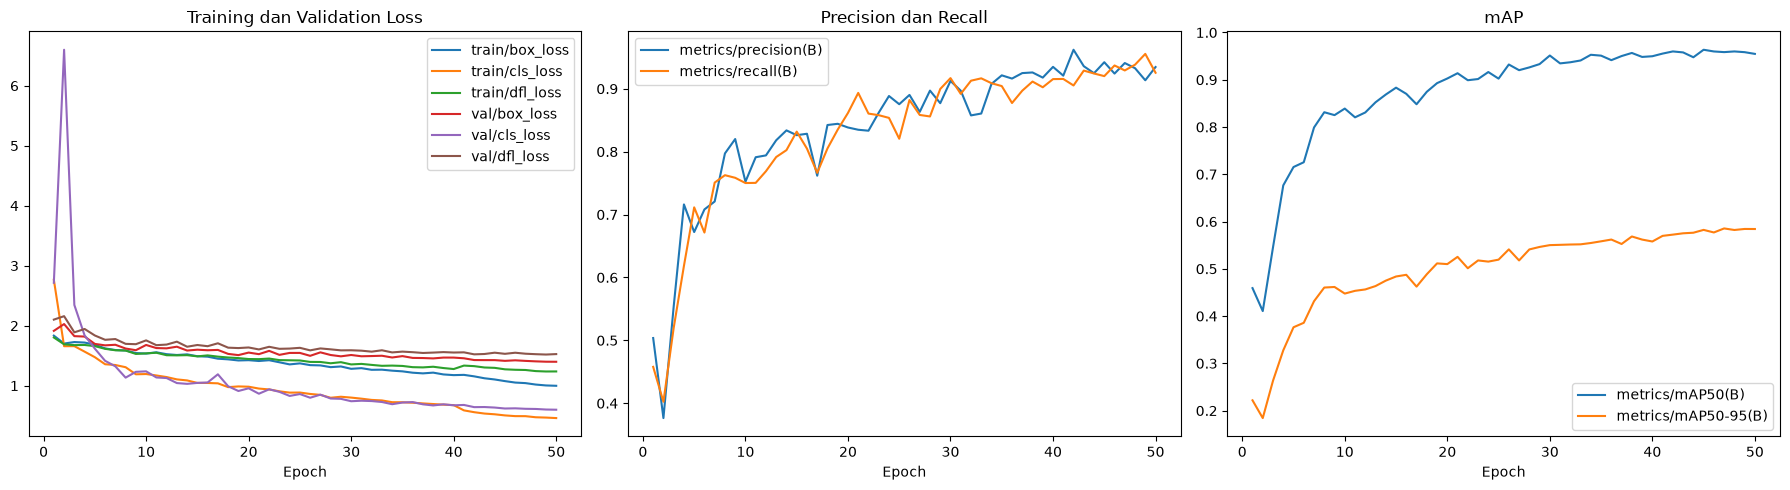

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

results_csv = RUN_DIR / 'results.csv'
history = pd.read_csv(results_csv)
history.columns = history.columns.str.strip()
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
loss_cols = [c for c in history.columns if 'loss' in c and ('train' in c or 'val' in c)]
for col in loss_cols:
    axes[0].plot(history['epoch'], history[col], label=col)
axes[0].set_title('Training dan Validation Loss')
axes[0].set_xlabel('Epoch'); axes[0].legend()
for col in ['metrics/precision(B)', 'metrics/recall(B)']:
    if col in history:
        axes[1].plot(history['epoch'], history[col], label=col)
axes[1].set_title('Precision dan Recall'); axes[1].set_xlabel('Epoch'); axes[1].legend()
for col in ['metrics/mAP50(B)', 'metrics/mAP50-95(B)']:
    if col in history:
        axes[2].plot(history['epoch'], history[col], label=col)
axes[2].set_title('mAP'); axes[2].set_xlabel('Epoch'); axes[2].legend()
plt.tight_layout()
plt.show()

## 4. Evaluasi pada test set

Sel ini mencetak mAP50, mAP50-95, precision, recall, serta precision, recall, dan AP50 untuk setiap kelas. IoU rata-rata dihitung sebagai IoU terbaik antara setiap ground-truth box dan prediksi dengan kelas yang sama.

In [6]:
from ultralytics.utils.metrics import box_iou
import numpy as np
import cv2

best_model = YOLO(str(BEST_WEIGHTS))
test_metrics = best_model.val(data=str(DATA_YAML), split='test', imgsz=IMG_SIZE, batch=8, plots=True)
print(f'mAP50    : {test_metrics.box.map50:.4f}')
print(f'mAP50-95 : {test_metrics.box.map:.4f}')
print(f'Precision: {test_metrics.box.mp:.4f}')
print(f'Recall   : {test_metrics.box.mr:.4f}')
print('\nMetrik per kelas:')
for i, name in enumerate(CLASS_NAMES):
    print(f'{name:12} precision={test_metrics.box.p[i]:.4f} recall={test_metrics.box.r[i]:.4f} AP50={test_metrics.box.ap50[i]:.4f}')

iou_values = []
test_images = [p for p in (DATASET_DIR / 'test' / 'images').glob('*') if p.suffix.lower() in IMAGE_EXTS]
for image_path in test_images:
    label_path = DATASET_DIR / 'test' / 'labels' / f'{image_path.stem}.txt'
    image = cv2.imread(str(image_path))
    if image is None or not label_path.exists():
        continue
    h, w = image.shape[:2]
    gt = []
    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) != 5:
            continue
        cls, xc, yc, bw, bh = map(float, parts)
        gt.append([cls, (xc-bw/2)*w, (yc-bh/2)*h, (xc+bw/2)*w, (yc+bh/2)*h])
    result = best_model.predict(source=str(image_path), imgsz=IMG_SIZE, conf=0.25, verbose=False)[0]
    for cls, x1, y1, x2, y2 in gt:
        candidates = result.boxes.xyxy[result.boxes.cls == int(cls)]
        if len(candidates):
            target = torch.tensor([[x1, y1, x2, y2]], device=candidates.device)
            iou_values.append(float(box_iou(target, candidates).max().item()))
print(f'IoU rata-rata (matching kelas): {np.mean(iou_values):.4f} dari {len(iou_values)} ground-truth box' if iou_values else 'IoU tidak dapat dihitung.')

Ultralytics 8.4.189  Python-3.14.6 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 70.4±21.9 MB/s, size: 34.5 KB)
val: Scanning D:\yolov11-training\datasets\MRI-Tumor-Dataset\test\labels... 246 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 246/246 2.0Kit/s 0.1s<0.1s
val: New cache created: D:\yolov11-training\datasets\MRI-Tumor-Dataset\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 1.9it/s 16.1s0.1s
                   all        246        250      0.952      0.931      0.966      0.606
                Glioma         80         84      0.963      0.926      0.965      0.653
            Meningioma         63         63      0.974      0.937      0.979      0.559
             Pituitary         49         49      0.951      0.918      0.955 

## 5. Deteksi pada beberapa gambar test


image 1/246 D:\yolov11-training\datasets\MRI-Tumor-Dataset\test\images\Tr-gl_0016_jpg.rf.99746694ea97fe0b73108832b462d48e.jpg: 640x640 1 Glioma, 176.0ms
image 2/246 D:\yolov11-training\datasets\MRI-Tumor-Dataset\test\images\Tr-gl_0018_jpg.rf.7a670766b8083a1b516a49e241a636bc.jpg: 640x640 1 Glioma, 170.0ms
image 3/246 D:\yolov11-training\datasets\MRI-Tumor-Dataset\test\images\Tr-gl_0028_jpg.rf.8098b9737048aac0dccb1b7c45046894.jpg: 640x640 1 Glioma, 16.7ms
image 4/246 D:\yolov11-training\datasets\MRI-Tumor-Dataset\test\images\Tr-gl_0032_jpg.rf.e1e485b4f909d84c8e24cd26e0ad3c08.jpg: 640x640 1 Glioma, 10.9ms
image 5/246 D:\yolov11-training\datasets\MRI-Tumor-Dataset\test\images\Tr-gl_0035_jpg.rf.7a7c96ab2e6245cf42a0c86b97f81b3e.jpg: 640x640 1 Glioma, 10.9ms
image 6/246 D:\yolov11-training\datasets\MRI-Tumor-Dataset\test\images\Tr-gl_0037_jpg.rf.6ac80086817a5d840d3b634956299e40.jpg: 640x640 1 Glioma, 11.1ms
image 7/246 D:\yolov11-training\datasets\MRI-Tumor-Dataset\test\images\Tr-gl_0040_jpg

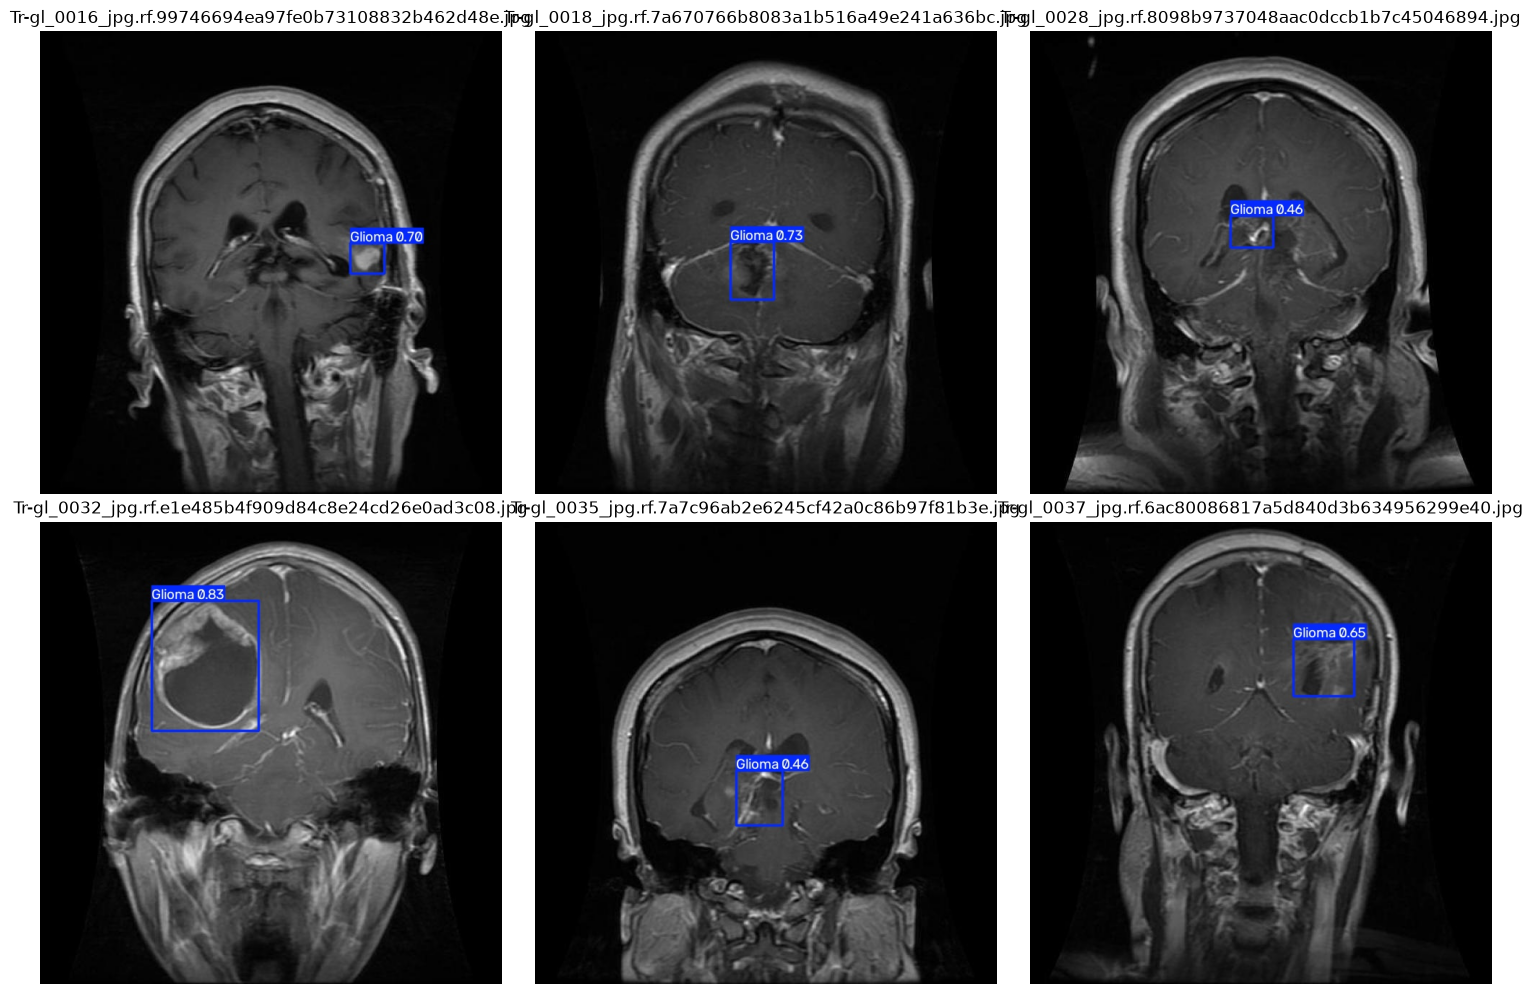

Hasil gambar: D:\yolov11-training\runs\brain-tumor-yolov11\test_predictions


In [7]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

IMAGE_OUTPUT_DIR = RUN_DIR / 'test_predictions'
best_model.predict(source=str(DATASET_DIR / 'test' / 'images'), conf=0.25, save=True, project=str(IMAGE_OUTPUT_DIR.parent), name=IMAGE_OUTPUT_DIR.name, exist_ok=True)
output_files = sorted(IMAGE_OUTPUT_DIR.glob('*'))[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, path in zip(axes.flat, output_files):
    ax.imshow(mpimg.imread(path)); ax.set_title(path.name); ax.axis('off')
for ax in axes.flat[len(output_files):]: ax.axis('off')
plt.tight_layout(); plt.show()
print('Hasil gambar:', IMAGE_OUTPUT_DIR)

## 6. Deteksi pada video

Isi `VIDEO_SOURCE` dengan path video pendek milik kelompok. Hasil `.mp4` akan disimpan sebagai artefak pengumpulan di folder `runs/custom_yolo11/video_predictions`.

In [ ]:
VIDEO_SOURCE = Path(r'.\data\test_video.mp4')
VIDEO_OUTPUT_DIR = RUN_DIR / 'video_predictions'
if VIDEO_SOURCE.exists():
    best_model.predict(source=str(VIDEO_SOURCE), conf=0.25, save=True, project=str(VIDEO_OUTPUT_DIR.parent), name=VIDEO_OUTPUT_DIR.name, exist_ok=True)
    print('Hasil video:', VIDEO_OUTPUT_DIR)
else:
    print(f'Video belum ditemukan: {VIDEO_SOURCE}. Isi VIDEO_SOURCE dengan file .mp4 lalu jalankan ulang sel ini.')

Gunakan grafik dan hasil test di atas untuk membahas: (1) gap training-validation loss sebagai indikasi overfitting/underfitting, (2) kelas dengan precision/recall terendah, (3) contoh false positive/false negative pada gambar dan video, serta (4) kendala ukuran/kontras MRI dan variasi posisi tumor. Bobot terbaik tersimpan di `runs/custom_yolo11/weights/best.pt` dan checkpoint tersimpan setiap 10 epoch.

Pada Windows, gunakan path dengan `Path(...)` seperti pada notebook ini; jangan menulis path Windows sebagai string biasa dengan backslash tunggal karena dapat terbaca sebagai escape character.